In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mt
import sklearn as sk
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Bidirectional, Dense, Embedding


In [2]:
df = pd.read_csv('train.csv')

In [3]:
x = df['comment_text']
y = df[df.columns[2:]].values
MAX_WORDS = 200000

In [4]:
vectoryzer = TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=1800, output_mode='int')

In [5]:
vectoryzer.adapt(x.values)
vectoryzed_text = vectoryzer(x.values)

In [6]:
dataset = tf.data.Dataset.from_tensor_slices((vectoryzed_text, y))
dataset = dataset.cache()
dataset = dataset.shuffle(160000)
dataset = dataset.batch(16)
dataset = dataset.prefetch(8)

In [7]:
batch_x, batch_y = dataset.as_numpy_iterator().next()

In [8]:
train = dataset.take(int(len(dataset)*.7))
val = dataset.skip(int(len(dataset)*.7)).take(int(len(dataset)*.2))
test = dataset.skip(int(len(dataset)*.9)).take(int(len(dataset)*.1))

In [9]:
model = Sequential()
model.add(Embedding(MAX_WORDS+1, 32))

# Bidirectional LSTM Layer
model.add(Bidirectional(LSTM(32, activation='tanh')))
# Feature extractor Fully connected layers
model.add(Dense(128, activation='relu'))
model.add(Dense(256, activation='relu'))
model.add(Dense(128, activation='relu'))
# Final layer 
model.add(Dense(6, activation='sigmoid'))

In [10]:
model.compile(loss='BinaryCrossentropy', optimizer='Adam')
model.summary()
history = model.fit(train, epochs=1, validation_data=val)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

6981/6981 ━━━━━━━━━━━━━━━━━━━━ 56165s 8s/step - loss: 0.0799 - val_loss: 0.0471


<Figure size 800x500 with 0 Axes>

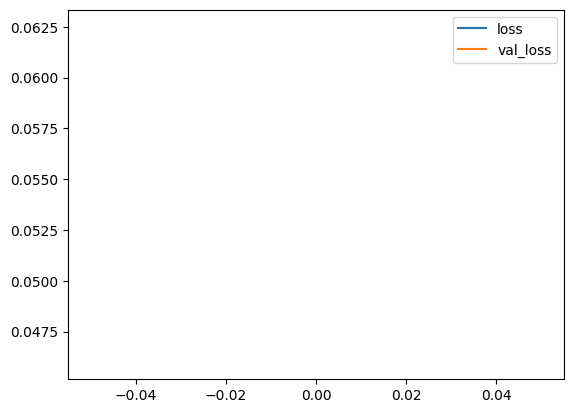

In [12]:
from matplotlib import pyplot as plt

plt.figure(figsize=(8,5))
pd.DataFrame(history.history).plot()
plt.show()


In [20]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split

# -----------------------------
# 1. Load dataset
# -----------------------------
df = pd.read_csv("train.csv")

texts = df['comment_text'].astype(str).tolist()

# Multi-label targets (6 columns)
labels = df[['toxic','severe_toxic','obscene','threat','insult','identity_hate']].values

# -----------------------------
# 2. Tokenization
# -----------------------------
MAX_WORDS = 20000       # vocab size
MAX_SEQUENCE_LEN = 150  # sequence length

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)
X = pad_sequences(sequences, maxlen=MAX_SEQUENCE_LEN, padding='post', truncating='post')

y = labels

# -----------------------------
# 3. Train-Test Split
# -----------------------------
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# 4. Build the Model
# -----------------------------
model = Sequential([
    Embedding(input_dim=MAX_WORDS+1, 
              output_dim=128, 
              input_length=MAX_SEQUENCE_LEN),
    LSTM(128, return_sequences=False),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(6, activation='sigmoid')   # 6 outputs for multi-label classification
])

model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

model.summary()

# -----------------------------
# 5. Train the Model
# -----------------------------
history = model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=128,
    validation_data=(X_val, y_val)
)

# -----------------------------
# 6. Evaluate
# -----------------------------
loss, acc = model.evaluate(X_val, y_val)
print(f"Validation Accuracy: {acc:.4f}")


/Users/midhunmanu/Developer/machine_learning/tensorflow-project/lib/python3.11/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
998/998 ━━━━━━━━━━━━━━━━━━━━ 216s 215ms/step - accuracy: 0.6584 - loss: 0.1736 - val_accuracy: 0.9940 - val_loss: 0.1391
Epoch 2/3
998/998 ━━━━━━━━━━━━━━━━━━━━ 212s 212ms/step - accuracy: 0.9781 - loss: 0.1292 - val_accuracy: 0.9941 - val_loss: 0.0546
Epoch 3/3
998/998 ━━━━━━━━━━━━━━━━━━━━ 216s 216ms/step - accuracy: 0.9941 - loss: 0.0527 - val_accuracy: 0.9941 - val_loss: 0.0494
998/998 ━━━━━━━━━━━━━━━━━━━━ 28s 29ms/step - accuracy: 0.9943 - loss: 0.0485
Validation Accuracy: 0.9941


In [21]:
# -----------------------------
# 6. Make Predictions
# -----------------------------
def predict_comment(text, tokenizer, model, max_len=150):
    # Convert text -> sequence
    seq = tokenizer.texts_to_sequences([text])
    padded = pad_sequences(seq, maxlen=max_len, padding='post', truncating='post')
    
    # Predict
    pred = model.predict(padded)[0]
    
    # Map results to labels
    labels = ['toxic','severe_toxic','obscene','threat','insult','identity_hate']
    results = {label: float(round(p, 3)) for label, p in zip(labels, pred)}
    return results

# Example predictions
examples = [
    "I hate you, you are the worst!",
    "Have a great day my friend 😊",
    "I will find you and hurt you"
]

for text in examples:
    print(f"\nComment: {text}")
    print(predict_comment(text, tokenizer, model))



Comment: I hate you, you are the worst!
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
{'toxic': 0.8270000219345093, 'severe_toxic': 0.024000000208616257, 'obscene': 0.41200000047683716, 'threat': 0.03099999949336052, 'insult': 0.4020000100135803, 'identity_hate': 0.06700000166893005}

Comment: Have a great day my friend 😊
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
{'toxic': 0.028999999165534973, 'severe_toxic': 0.0, 'obscene': 0.003000000026077032, 'threat': 0.0, 'insult': 0.003000000026077032, 'identity_hate': 0.0}

Comment: I will find you and hurt you
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
{'toxic': 0.38499999046325684, 'severe_toxic': 0.0020000000949949026, 'obscene': 0.08699999749660492, 'threat': 0.008999999612569809, 'insult': 0.12099999934434891, 'identity_hate': 0.017999999225139618}


model.save("toxic_comment.h5")